In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

In [3]:
df = pd.DataFrame(pd.read_csv('../data/preprocessed/model_data.csv'))

In [4]:
target_col = "future_rv_20d"

features = [
    "rv_5d",
    "rv_20d",
    "rv_60d",
    "vix_close"
]

required_cols = ["date", target_col] + features
df = df[required_cols].dropna().reset_index(drop=True)

print("Dataset shape:", df.shape)
print("Date range:", df["date"].min(), df["date"].max())

Dataset shape: (3041, 6)
Date range: 2010-01-04 2022-10-26


In [5]:
n = len(df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

horizon = 20

train = df.iloc[:train_end - horizon].copy()
val = df.iloc[train_end:val_end - horizon].copy()
test = df.iloc[val_end:].copy()

In [6]:
def evaluate_model(y_true, y_pred, model_name):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse
    }

results = []
predictions = {}

In [7]:
y_test = test[target_col]

pred_persistence = test["rv_20d"].to_numpy()

results.append(
    evaluate_model(
        y_test,
        pred_persistence,
        "Persistence RV-20"
    )
)

predictions["Persistence"] = pred_persistence

In [8]:
har_features = [
    "rv_5d",
    "rv_20d",
    "rv_60d"
]

X_train_har = train[har_features]
y_train = train[target_col]

X_val_har = val[har_features]
y_val = val[target_col]

X_test_har = test[har_features]

In [9]:
har_model = LinearRegression()

har_model.fit(
    X_train_har,
    y_train
)

pred_har = har_model.predict(X_test_har)

results.append(
    evaluate_model(
        y_test,
        pred_har,
        "HAR-RV"
    )
)

predictions["HAR-RV"] = pred_har

In [10]:
har_coefficients = pd.DataFrame({
    "Feature": har_features,
    "Coefficient": har_model.coef_
})

print(har_coefficients)
print("Intercept:", har_model.intercept_)

  Feature  Coefficient
0   rv_5d     0.214692
1  rv_20d     0.163442
2  rv_60d     0.234445
Intercept: 0.050959975722696255


In [11]:
har_vix_features = [
    "rv_5d",
    "rv_20d",
    "rv_60d",
    "vix_close"
]

X_train_har_vix = train[har_vix_features]
X_test_har_vix = test[har_vix_features]

har_vix_model = LinearRegression()

har_vix_model.fit(
    X_train_har_vix,
    y_train
)

pred_har_vix = har_vix_model.predict(
    X_test_har_vix
)

results.append(
    evaluate_model(
        y_test,
        pred_har_vix,
        "HAR-RV + VIX"
    )
)

predictions["HAR-RV + VIX"] = pred_har_vix

In [12]:
df["vix_close"] = df["vix_close"] / 100

In [13]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values("MAE")

display(results_df)

,Model,MAE,RMSE
2,HAR-RV + VIX,0.041456,0.051962
1,HAR-RV,0.041501,0.052902
0,Persistence RV-20,0.049013,0.062087


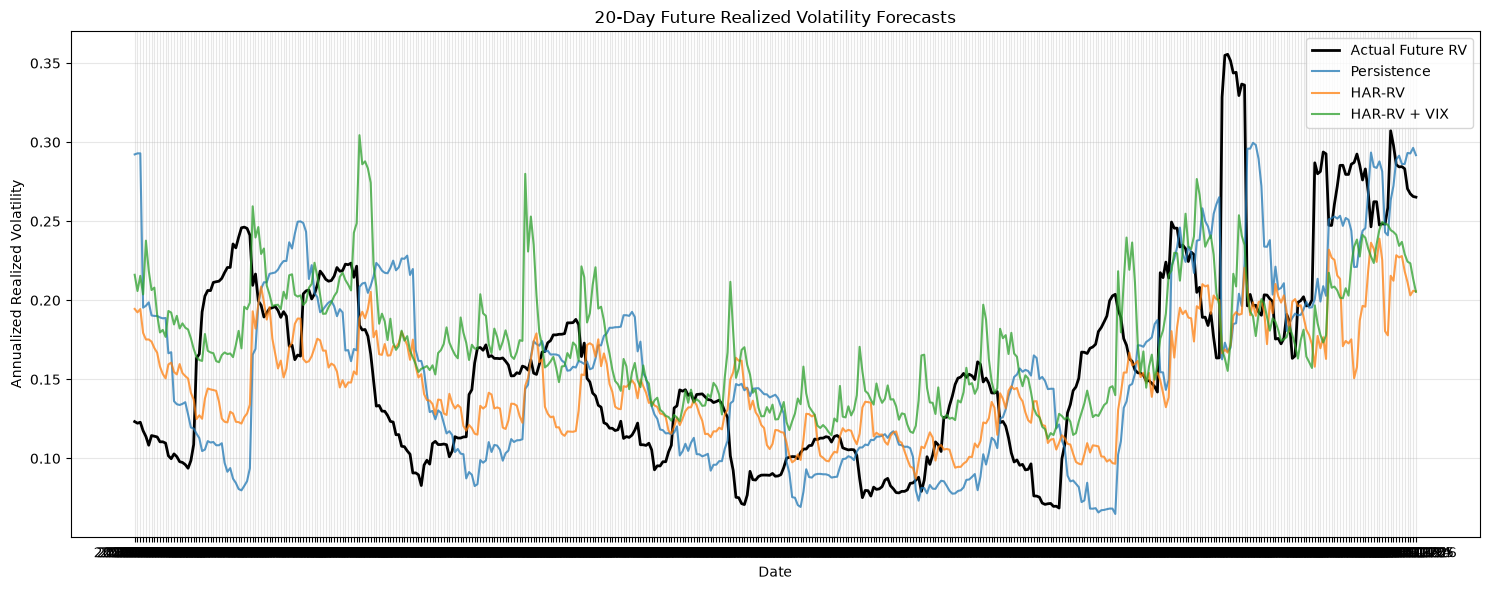

In [14]:
plt.figure(figsize=(15, 6))

plt.plot(
    test["date"],
    y_test,
    label="Actual Future RV",
    color="black",
    linewidth=2
)

for model_name, pred in predictions.items():
    plt.plot(
        test["date"],
        pred,
        label=model_name,
        alpha=0.75
    )

plt.title("20-Day Future Realized Volatility Forecasts")
plt.xlabel("Date")
plt.ylabel("Annualized Realized Volatility")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
def qlike(y_true, y_pred, eps=1e-8):
    actual_var = np.maximum(np.asarray(y_true) ** 2, eps)
    predicted_var = np.maximum(np.asarray(y_pred) ** 2, eps)

    return np.mean(
        np.log(predicted_var)
        + actual_var / predicted_var
    )

In [16]:
for row in results:
    model_name = row['Model']

    key = {
        'Persistence RV-20': 'Persistence',
        'HAR-RV': 'HAR-RV',
        'HAR-RV + VIX': 'HAR-RV + VIX' 
    }[model_name]

    row['QLIKE'] = qlike(
        y_test,
        predictions[key]
    )

results_df = pd.DataFrame(results)
display(results_df.sort_values("MAE"))

,Model,MAE,RMSE,QLIKE
2,HAR-RV + VIX,0.041456,0.051962,-2.641724
1,HAR-RV,0.041501,0.052902,-2.579144
0,Persistence RV-20,0.049013,0.062087,-2.350932


MAE: 0.041456 -> error of 4.15% annualized volatility.
HAR-RV reduces MAE by about 15%->Historical volatility has value over simply assuming the next few days will be like the previous few days.

In [17]:
from sklearn.metrics import mean_absolute_error

har_features = [
    "rv_5d",
    "rv_20d",
    "rv_60d",
    "vix_close"
]

har_val_pred = har_vix_model.predict(
    val[har_features]
)

har_val_mae = mean_absolute_error(
    val["future_rv_20d"],
    har_val_pred
)

print(f"HAR-RV + VIX Validation MAE: {har_val_mae:.6f}")

HAR-RV + VIX Validation MAE: 0.073434
